# 2.4 Recipe Geomagnetik: Koreksi Diurnal dan IGRF, Anomali Residual, serta Zona Anomali

**Nama:** Mohammad Iqfar  
**NIM:** H061251064 (Kelas B, Geofisika)  
**Rujukan:** *AI Cookbook untuk Earth Sciences* Bagian 2.4, dan Bagian 3 notebook *TUGAS AI GEOFISIKA OUTPUT*  
**Recipe ID:** R-MAG-001 | **Prompt ID:** P-MAG-001 | **Equation ID:** E-MAG-001, E-MAG-002  
**File kode (terpisah):** `r-mag-001-geomagnetik.py`

## 2.4.0 Mengapa Bagian Geomagnetik yang Dipilih

Dari lima bagian di tugasmu, geomagnetik paling cocok untuk recipe berbasis visualisasi karena datanya berupa **grid 2D** yang hasilnya bisa dilihat langsung sebagai peta, profil, dan zona.

| Bagian tugas | Visualisasi asli | Penilaian |
|---|---|---|
| Seismik (Wadati) | seismogram, diagram Wadati | bagus, tetapi 2 grafik 1D |
| Gravitasi (Airy/Pratt) | penampang 2 panel | bagus, tetapi model teoretis, bukan data survei |
| **Geomagnetik** | **peta kontur 3 panel, variasi diurnal, peta zona** | **terbaik: alur data mentah → koreksi → interpretasi terlihat jelas di peta** |
| Geolistrik | satu kurva sounding | satu grafik |
| Georadar | radargram, stack envelope | bagus, tetapi pemrosesan sinyal lebih rumit |

Recipe ini memakai alur yang sama dengan tugasmu, lalu menambah visualisasi: peta data mentah, urutan akuisisi, profil lintasan, penanda puncak anomali, histogram, dan peta galat. Totalnya **6 grafik**. Semua angka di dokumen ini berasal dari eksekusi kode dan sama dengan output notebookmu (RMSE terkoreksi 1,62 nT).

---

## 2.4.1 Problem

**Pertanyaan ilmiah.** Dari data medan magnet total pada grid survei 21 × 21 titik dan rekaman base station, bagaimana mendapatkan **anomali magnet residual** dan menentukan **zona anomali positif dan negatif yang signifikan**?

**Pengguna dan keputusan.** Mahasiswa atau analis survei magnetik yang perlu peta anomali bersih sebagai dasar interpretasi awal keberadaan benda termagnetisasi di bawah permukaan.

**Batas recipe.** Satu outcome: peta anomali residual dan daftar zona signifikan. Recipe **tidak** melakukan inversi kedalaman atau bentuk benda, dan **tidak** menghitung IGRF sendiri (nilai IGRF adalah *placeholder* yang harus diambil dari kalkulator NOAA).

---

## 2.4.2 Minimal Theory dan Asumsi

**Anomali medan total** (E-MAG-001):

$$\Delta T(x,y) = F_{\text{obs, terkoreksi diurnal}}(x,y) - F_{\text{IGRF}}(x,y)$$

**Koreksi diurnal** memakai base station yang diam (E-MAG-002):

$$F_{\text{terkoreksi}}(t) = F_{\text{obs}}(t) - \big[B(t) - B_{\text{ref}}\big]$$

**Model benda sintetis** (dipol terinduksi, pendekatan bola):

$$\Delta T = A\,\frac{3\cos^2\theta - 1}{r^3}$$

dengan $r$ jarak dari titik ukur ke benda, $\theta$ sudut antara vektor $r$ dan arah medan utama, dan $A$ kekuatan magnetisasi (A negatif berarti magnetisasi berlawanan arah).

**Asumsi.** (1) IGRF diperlakukan sebagai medan regional yang bervariasi linear di area survei. (2) Variasi harian di lokasi survei sama dengan di base station. (3) Benda berupa dipol terinduksi (bola). (4) Satuan medan: nT.

**Mengapa muncul pasangan positif dan negatif.** Pada inklinasi menengah (di sini −30°), anomali benda tunggal selalu berupa pasangan kutub positif dan negatif, bukan satu puncak. Ini bukan dua benda.

---

## 2.4.3 Kontrak Input dan Constraint

**Input (sintetis, di memori, seed 44).**
- Grid 21 × 21 titik, spasi 10 m (area 200 × 200 m), 441 titik, 20 detik per titik mulai pukul 9,00.
- IGRF placeholder: $F_0$ = 43 500 nT, gradien 0,002 nT/m (timur) dan 0,020 nT/m (utara), inklinasi −30°, deklinasi 0°.
- Dua benda: benda 1 di (80, 100) m kedalaman 15 m, $A = +3{,}0\times10^5$; benda 2 di (150, 60) m kedalaman 10 m, $A = -1{,}5\times10^5$.
- Variasi diurnal: gelombang 24 jam (amplitudo 12 nT) ditambah gelombang 3 jam (4 nT). Noise survei 1,5 nT, noise base station 0,5 nT.
- Base station: satu bacaan per menit.

**Constraint.**
1. Hanya NumPy, pandas, matplotlib.
2. Data mentah (`raw`) tidak boleh berubah; hasil koreksi masuk ke kolom baru pada salinan `data`.
3. Tidak ada file yang dibuat; semua output tampil di terminal dan grafik.
4. Satuan nT dinyatakan eksplisit, dan IGRF dinyatakan sebagai input eksternal.

---

## 2.4.4 Prompt (P-MAG-001)

```text
R : Scientific Python developer dan reviewer data geomagnetik.

T : Koreksi data medan magnet total terhadap variasi diurnal (base station)
    dan IGRF, hitung anomali residual dT, lalu identifikasi zona anomali
    positif dan negatif yang signifikan (|dT - mean| > 1 sigma).

C : Latihan survei magnetik pada grid 21 x 21 titik. Hasil dipakai untuk
    interpretasi awal; bukan inversi kedalaman atau litologi.

I : Data sintetis di memori (seed tetap) dengan dua benda dipol terinduksi.
    IGRF adalah placeholder (F0, gradien, inklinasi, deklinasi); nyatakan
    bahwa nilai nyata harus diambil dari kalkulator NOAA. Tandai bagian
    yang harus diganti jika memakai data lapangan.

K : - Hanya NumPy, pandas, matplotlib. Jangan buat atau tulis file.
    - Data mentah tidak boleh diubah; hasil koreksi di kolom baru.
    - Tampilkan semua hasil di terminal dan grafik; satuan nT.
    - Jangan menyimpulkan litologi dari anomali magnet.

O : - Tabel statistik anomali (mean, std, min, max) dan RMSE vs nilai benar,
      dengan dan tanpa koreksi diurnal.
    - Tabel zona signifikan: jenis, jumlah titik, puncak dT, posisi puncak.
    - 6 grafik: data mentah, variasi diurnal, 3 peta kontur (sebenarnya,
      tanpa koreksi, terkoreksi), profil lintasan, peta zona, histogram
      dan peta galat.

Q : - Koreksi diurnal harus menurunkan RMSE.
    - RMSE terkoreksi < 3 nT.
    - Zona positif dan negatif terdeteksi dalam 20 m dari benda sebenarnya.

V : Bandingkan IGRF dengan kalkulator NOAA (data nyata), cek data mentah
    tidak berubah, dan cetak status Executed atau Partial dari check.
```

---

## 2.4.5 Code, Dijelaskan per Bagian

Kode lengkap ada di file terpisah **`r-mag-001-geomagnetik.py`**. File dibagi menjadi 4 bagian dengan penanda `# %%` (Jupyter cell). Di VS Code kamu bisa menjalankan seluruh file dengan tombol Run, atau satu bagian dengan **Run Cell**. Cuplikan di bawah hanya baris kunci untuk penjelasan.

**Cara menjalankan.**
1. Buka `r-mag-001-geomagnetik.py` di VS Code.
2. Terminal (Ctrl + `): `pip install numpy pandas matplotlib`
3. Cara paling nyaman: klik kanan di editor, pilih **Run Current File in Interactive Window** (atau klik **Run Cell** pada tanda `# %%`). Tabel, angka, dan **6 grafik tampil langsung di panel VS Code**, berurutan, tanpa file apa pun disimpan.
4. Alternatif: `python r-mag-001-geomagnetik.py` di terminal. Grafik muncul di jendela terpisah (tutup satu jendela untuk melihat berikutnya).

> Fungsi `tampil()` di kode merender grafik ke **memori** (bukan ke disk) dan menampilkannya di panel. Ini mengatasi peringatan *FigureCanvasAgg is non-interactive, and thus cannot be shown* yang muncul jika backend matplotlib tidak interaktif.

### Bagian 0: Import dan konfigurasi

```python
import numpy as np, pandas as pd, matplotlib.pyplot as plt
SEED = 42
```

- NumPy untuk perhitungan array dan grid, pandas untuk tabel data, matplotlib untuk grafik.
- `pd.set_option` mengatur format angka (3 desimal), `plt.rcParams.update` mengatur resolusi dan grid.
- `SEED = 42` menjaga noise acak tetap sama setiap run. Bagian 3A memakai `SEED + 2` (yaitu 44) supaya sama dengan notebookmu.

### Bagian 3A: Data survei sintetis

**Tujuan:** membuat data survei buatan dengan jawaban yang diketahui, sehingga hasil koreksi bisa diuji.

**(a) Grid dan arah medan.**

```python
X, Y = np.meshgrid(xs, ys)
Fhat = np.array([np.cos(I)*np.sin(D_), np.cos(I)*np.cos(D_), np.sin(I)])
```

- `np.meshgrid` mengubah dua vektor (`xs`, `ys`) menjadi dua matriks 21 × 21 berisi koordinat setiap titik.
- `Fhat` adalah vektor satuan arah medan utama (timur, utara, bawah) dari inklinasi `I` dan deklinasi `D_`. Dibutuhkan untuk menghitung sudut $\theta$ pada rumus dipol.

**(b) Anomali benda: `dipole_anomaly`.**

```python
r = np.sqrt(rx**2 + ry**2 + rz**2)
cosang = (Fhat[0]*rx + Fhat[1]*ry + Fhat[2]*rz) / r
return A * (3*cosang**2 - 1) / r**3
```

- `rx, ry, rz` adalah vektor dari benda ke tiap titik ukur (`rz` negatif karena benda di bawah permukaan).
- `cosang` adalah cosinus sudut antara vektor itu dan arah medan (hasil kali titik dibagi panjang).
- Anomali turun cepat dengan jarak (`1/r³`), jadi benda dangkal menghasilkan anomali sempit dan kuat.
- `anom_true` menjumlahkan dua benda. Benda 2 memakai `A` negatif, sehingga polaritasnya terbalik.

**(c) Variasi harian dan data "terukur".**

```python
t_hours = 9.0 + np.arange(n)*20/3600
diurnal = 12*np.sin(2*np.pi*(t_hours-6)/24) + 4*np.sin(2*np.pi*(t_hours-6)/3)
F_obs = igrf_grid.ravel() + diurnal + anom_true.ravel() + rng.normal(0, 1.5, n)
```

- Tiap titik diukur dalam 20 detik, jadi waktu naik 20/3600 jam per titik.
- `diurnal` adalah variasi harian buatan: gelombang lambat (24 jam) ditambah gelombang cepat (3 jam).
- **Persamaan kunci:** medan terukur = IGRF + variasi harian + anomali benda + noise. Tugas kita adalah memisahkan anomali dari tiga komponen lainnya.
- `.ravel()` meratakan matriks 2D menjadi vektor agar sejajar dengan `t_hours`.
- Base station (`B`) merekam variasi harian yang sama dengan noise 0,5 nT, satu bacaan per menit.

**(d) Grafik 1: data mentah.** Panel kiri: peta medan total mentah. Titik-titik di sekitar (80, 100) m dan (150, 60) m sudah tampak menyimpang (kuning dan biru tua), tetapi nilai latar belakang di tempat lain masih sekitar 43 500 nT dan belum bersih dari IGRF serta variasi harian. Panel kanan: urutan akuisisi; warna menunjukkan waktu tiap titik diukur, dari lintasan selatan (sekitar jam 9,0) sampai utara (sekitar jam 11,4). Titik yang berbeda diukur pada jam berbeda, sehingga koreksi diurnal diperlukan.

### Bagian 3B: Koreksi diurnal, koreksi IGRF, anomali residual

**Tujuan:** membersihkan data langkah demi langkah sampai tinggal anomali benda.

```python
B_at_obs = np.interp(data["waktu (jam)"], tb, B)
data["Koreksi diurnal (nT)"] = B_at_obs - IGRF_BASE
data["F_terkoreksi (nT)"] = data["F_obs (nT)"] - data["Koreksi diurnal (nT)"]
data["Anomali dT (nT)"] = data["F_terkoreksi (nT)"] - data["IGRF (nT)"]
```

- `np.interp` mencari nilai base station tepat pada waktu setiap titik ukur (base station direkam tiap menit, titik ukur tiap 20 detik, jadi perlu interpolasi).
- Koreksi diurnal = bacaan base station dikurangi nilai referensinya. Hasilnya dikurangkan dari data terukur (E-MAG-002).
- IGRF di tiap titik dihitung dari $F_0$ dan gradien linear. Mengurangkannya memberi anomali dT (E-MAG-001).
- `data = raw.copy()` menjaga `raw` tidak berubah (constraint 2).
- `dT_nodiurnal` adalah pembanding: anomali yang dihitung **tanpa** koreksi diurnal.
- `rmse_raw` dan `rmse_corr` mengukur seberapa jauh kedua hasil dari anomali sebenarnya.

**Hasil numerik:**

| Besaran | Nilai |
|---|---|
| Mean dT | 0,08 nT |
| Std dT | 9,47 nT |
| Min / Max dT | −95,6 / +74,5 nT |
| RMSE tanpa koreksi diurnal | **11,43 nT** |
| RMSE terkoreksi | **1,62 nT** |

Koreksi diurnal menurunkan galat sekitar **7 kali lipat**.

**Grafik 2: variasi diurnal.** Garis biru = rekaman base station (naik-turun lambat dengan riak kecil), titik merah = nilai koreksi yang dipakai pada waktu tiap titik ukur. Titik merah mengikuti garis biru, yang menunjukkan interpolasi bekerja.

**Grafik 3: tiga peta kontur dengan skala warna sama.**
- Kiri: anomali sebenarnya, dua pasang kutub merah-biru.
- Tengah: tanpa koreksi diurnal; latar belakang berwarna merah muda dan pola pita menyebar karena variasi harian ikut terbaca.
- Kanan: terkoreksi, latar bersih dan sangat mirip peta kiri.

Skala warna dibuat sama (`vmin=-vmax, vmax=vmax`) supaya perbandingan ketiganya jujur.

**Grafik 4: profil lintasan.** Garis putus-putus hitam = sebenarnya, oranye = tanpa koreksi, biru = terkoreksi. Profil `y = 100 m` melewati benda 1, profil `y = 60 m` melewati benda 2. Kurva oranye bergeser (offset) naik beberapa nT dari kurva sebenarnya, kurva biru menempel pada garis hitam. Grafik ini menunjukkan efek koreksi paling jelas.

### Bagian 3C: Identifikasi zona anomali

**Tujuan:** mengubah peta menjadi daftar zona anomali yang bisa dilaporkan.

**(a) Ambang signifikan.**

```python
mask = sign*(dT - mu) > 1.0*sd
```

- Sel dianggap signifikan jika menyimpang lebih dari 1σ dari rata-rata. `sign = +1` untuk zona positif dan `−1` untuk negatif.
- Ambang 1σ adalah pilihan praktis, bukan angka mutlak. Menaikkan ke 2σ membuat zona lebih sedikit dan lebih kecil.

**(b) Pelabelan zona: `label_regions`.**

```python
stack = [(i, j)]
while stack:
    a, b = stack.pop()
    for da, db in ((1,0),(-1,0),(0,1),(0,-1)):
        ...
```

- Ini algoritma *flood-fill* dengan tumpukan (stack). Dari satu sel signifikan, algoritma menyebar ke 4 tetangga (atas, bawah, kiri, kanan) yang juga signifikan dan memberi nomor yang sama.
- Hasilnya, sel yang saling bersambung menjadi satu zona bernomor. Ditulis manual agar tidak butuh SciPy.

**(c) Ringkasan tiap zona.**

```python
if sel.sum() < 3: continue
idx = np.argmax(np.abs(np.where(sel, dT, 0)))
iy, ix = np.unravel_index(idx, dT.shape)
```

- Zona kurang dari 3 titik dibuang karena kemungkinan besar noise.
- Puncak zona = titik dengan |dT| terbesar di dalam zona. `np.unravel_index` mengubah indeks datar kembali menjadi baris dan kolom, lalu diterjemahkan ke koordinat x dan y.

**Hasil: 4 zona terdeteksi.**

| Zona | Jumlah titik | Puncak dT (nT) | x (m) | y (m) | Terkait benda |
|---|---|---|---|---|---|
| Negatif | 7 | −95,6 | 150 | 70 | benda 2 |
| Positif | 9 | +74,5 | 80 | 110 | benda 1 |
| Negatif | 11 | −54,0 | 80 | 90 | benda 1 |
| Positif | 9 | +44,4 | 150 | 50 | benda 2 |

Benda 1 ($A$ positif) menghasilkan puncak positif di utara dan negatif di selatan titik (80, 100). Benda 2 ($A$ negatif) polaritasnya terbalik: negatif di utara dan positif di selatan titik (150, 60). Setiap benda menghasilkan **sepasang** zona, bukan satu.

**Grafik 5: peta zona signifikan.** Kontur garis tegas = batas +1σ, putus-putus = batas −1σ. Lingkaran = puncak positif, kotak = puncak negatif, dengan label nT. Bintang emas = posisi benda sebenarnya, berada **di antara** pasangan puncak, bukan tepat di puncak. Inilah alasan mengapa puncak anomali bukan lokasi benda.

**Grafik 6: histogram dan peta galat.**
- Kiri: histogram dT. Sebagian besar titik terkumpul dekat nol, dan ekor panjang di kedua sisi adalah anomali. Garis vertikal = ambang ±1σ.
- Kanan: peta galat (terkoreksi dikurangi sebenarnya). Pola acak tanpa struktur menunjukkan bahwa yang tersisa hanya noise (±5 nT), bukan sinyal benda yang belum terkoreksi.

### Bagian 3D: Verifikasi dan kriteria mutu

```python
checks = {"Koreksi diurnal menurunkan RMSE": rmse_corr < rmse_raw, ...}
def dekat(df_, bx, by, tol=20.0): ...
```

- Mencetak IGRF di satu titik (43 502,20 nT di (100, 100)) sebagai bahan perbandingan dengan kalkulator NOAA saat memakai data nyata.
- `checks` berisi 6 kriteria, termasuk kedekatan zona dengan posisi benda sebenarnya (fungsi `dekat` menghitung jarak terkecil dari puncak ke benda, toleransi 20 m).
- Status dicetak otomatis dari hasil check.

---

## 2.4.6 Result

Dijalankan pada Python 3.12.3, NumPy 2.4.4, pandas 3.0.2, exit code 0. Hasil harus sama di komputermu karena seed tetap.

| Parameter | Hasil |
|---|---|
| Titik survei | 441 (21 × 21, spasi 10 m) |
| RMSE tanpa koreksi diurnal | 11,43 nT |
| RMSE terkoreksi | 1,62 nT |
| Zona signifikan | 4 (2 positif, 2 negatif) |
| Status | **Executed** |

**Interpretasi.** Dua pasang anomali dipol menunjukkan dua benda termagnetisasi: benda 1 di sekitar (80, 100) m dengan magnetisasi searah medan utama, dan benda 2 di sekitar (150, 60) m dengan polaritas terbalik, yang pada data nyata bisa menandakan magnetisasi remanen berlawanan arah. Interpretasi ini hanya menyatakan **kontras magnetisasi**, bukan jenis batuan.

**Batas klaim.** Data sintetis hanya membuktikan implementasi benar. IGRF di sini placeholder, sehingga pada data lapangan nilainya harus diganti dari kalkulator NOAA sesuai lokasi dan tanggal survei.

---

## 2.4.7 Optional Check

| Check | Kriteria | Status |
|---|---|---|
| Data mentah tidak berubah | `np.allclose` | Lulus |
| Koreksi diurnal membantu | RMSE terkoreksi < RMSE tanpa koreksi | Lulus |
| Akurasi anomali | RMSE < 3 nT (nyata: 1,62) | Lulus |
| Zona positif dekat benda 1 | ≤ 20 m (nyata: 10 m) | Lulus |
| Zona negatif dekat benda 1 | ≤ 20 m (nyata: 10 m) | Lulus |
| Zona dekat benda 2 | ≤ 20 m (nyata: 10 m) | Lulus |

**Eksperimen yang disarankan.**
1. Naikkan amplitudo diurnal dari 12 menjadi 40 nT (di `diurnal` dan `B`) dan lihat RMSE tanpa koreksi membesar, sedangkan RMSE terkoreksi tetap kecil.
2. Ubah ambang `1.0*sd` menjadi `2.0*sd` pada Bagian 3C dan amati zona mengecil.
3. Ubah `INC_DEG` menjadi −90 (inklinasi vertikal). Anomali menjadi simetris dengan puncak positif tepat di atas benda.

---

## 2.4.8 Pitfall

- **Memakai IGRF placeholder untuk data nyata.** Nilai harus dari kalkulator NOAA sesuai lokasi dan tanggal survei.
- **Mengabaikan koreksi diurnal.** Titik yang diukur pada jam berbeda terbaca berbeda walau tidak ada anomali; efeknya terlihat pada Grafik 3 dan 4.
- **Menganggap puncak anomali sama dengan posisi benda.** Pada inklinasi menengah, benda berada di antara pasangan puncak positif dan negatif.
- **Menganggap pasangan positif dan negatif sebagai dua benda.** Itu ciri khas anomali dipol tunggal.
- **Menyimpulkan litologi.** Anomali magnet hanya menunjukkan kontras magnetisasi.
- **Menganggap ambang 1σ sebagai kebenaran.** Itu pilihan analis; laporkan ambang yang dipakai.

---

## 2.4.9 Tautan Identifier

| ID | Jenis | Lokasi |
|---|---|---|
| P-MAG-001 | Prompt | Bagian 2.4.4 |
| R-MAG-001 | Recipe | Dokumen ini |
| E-MAG-001, E-MAG-002 | Equation | Bagian 2.4.2 |
| - | Source code | `r-mag-001-geomagnetik.py` (file terpisah) |
| - | Referensi tugas | Bagian 3 notebook *TUGAS AI GEOFISIKA OUTPUT* |

# Code 

NumPy 2.4.4 | pandas 3.0.5
Data mentah (tidak diubah): (441, 4)
 x (m)  y (m)  waktu (jam)  F_obs (nT)
 0.000  0.000        9.000  43,510.699
10.000  0.000        9.006  43,508.787
20.000  0.000        9.011  43,509.234
30.000  0.000        9.017  43,510.565
40.000  0.000        9.022  43,510.218


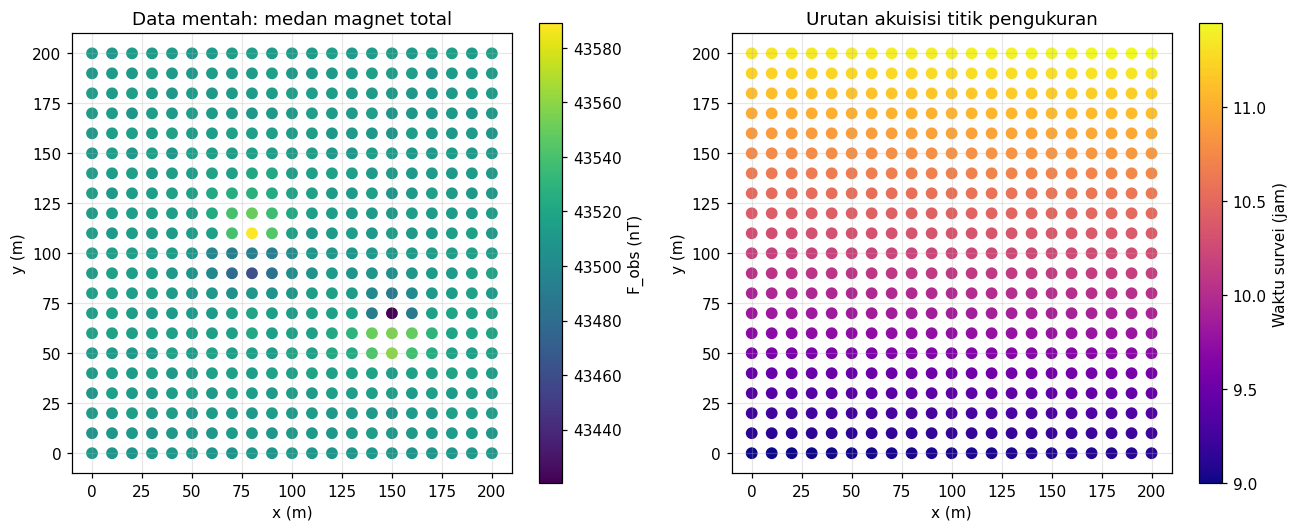

Statistik anomali: mean = 0.08 nT | std = 9.47 nT | min = -95.6 | max = 74.5
RMSE vs anomali sebenarnya: tanpa koreksi diurnal = 11.43 nT | terkoreksi = 1.62 nT


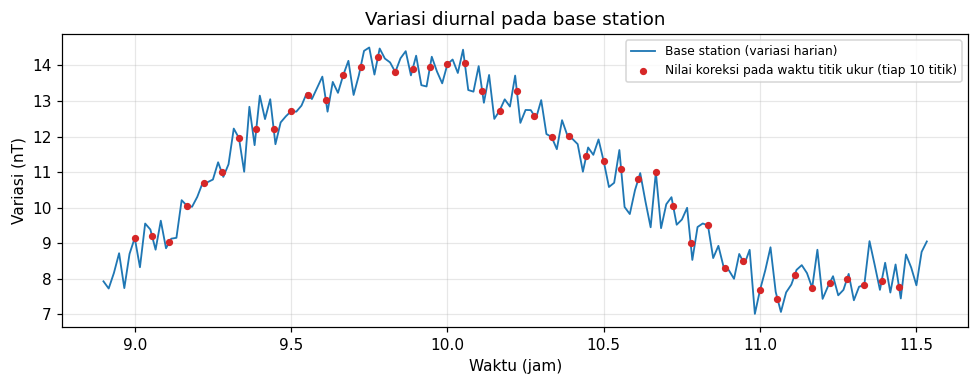

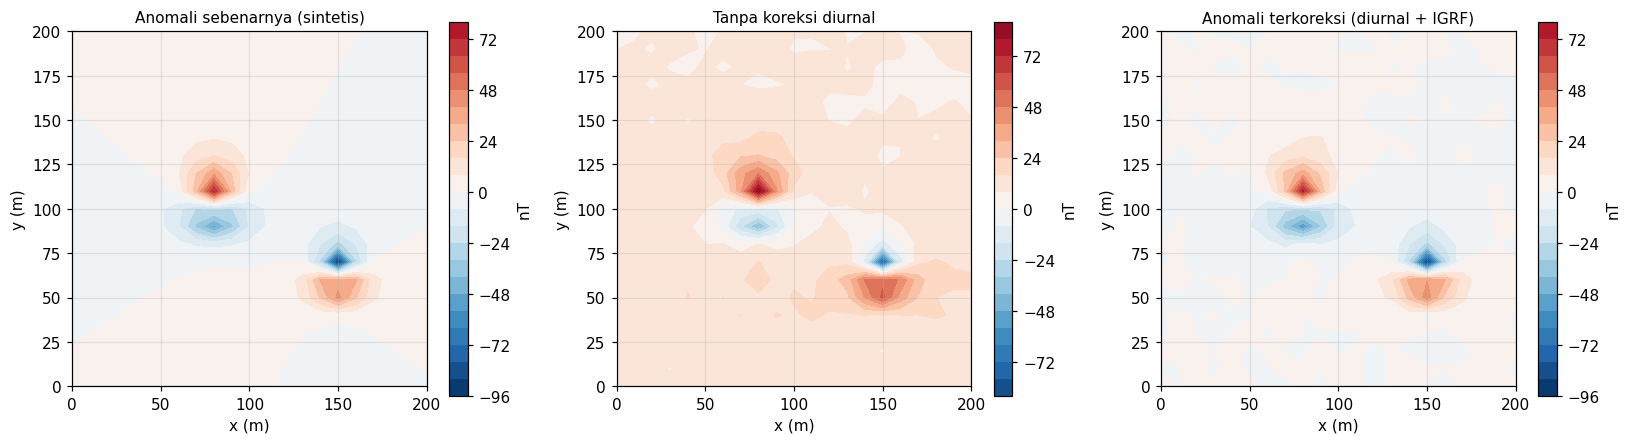

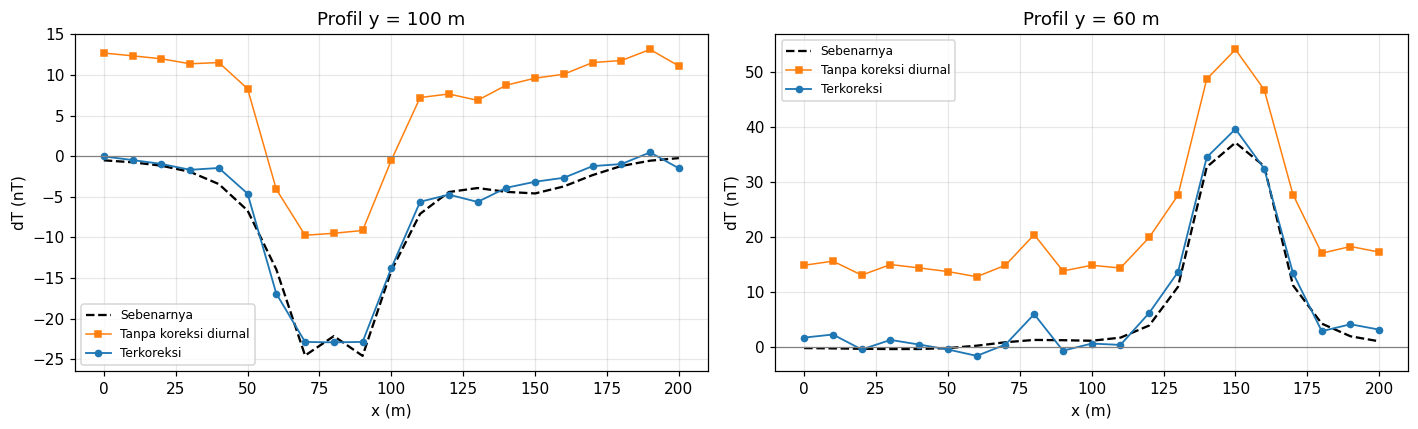

      Zona  Jumlah titik  Puncak dT (nT)  x puncak (m)  y puncak (m)
0  Negatif             7         -95.554       150.000        70.000
1  Positif             9          74.542        80.000       110.000
2  Negatif            11         -54.018        80.000        90.000
3  Positif             9          44.398       150.000        50.000


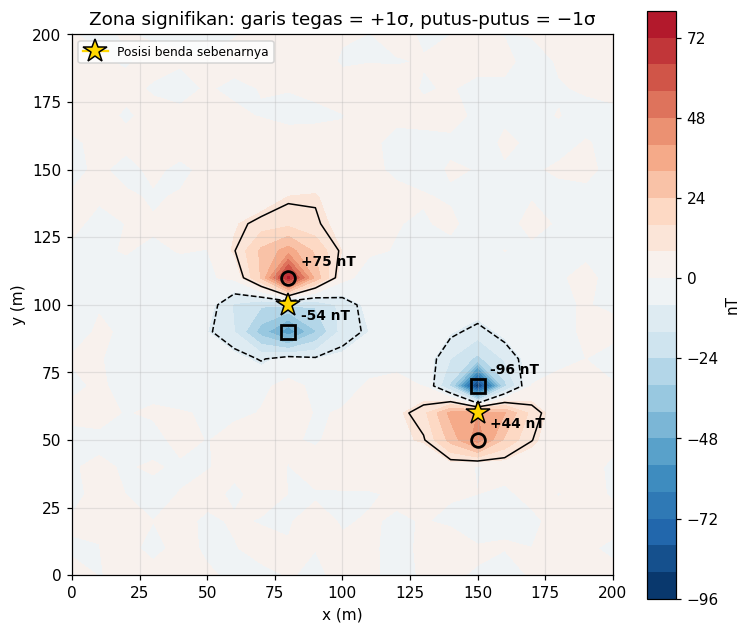

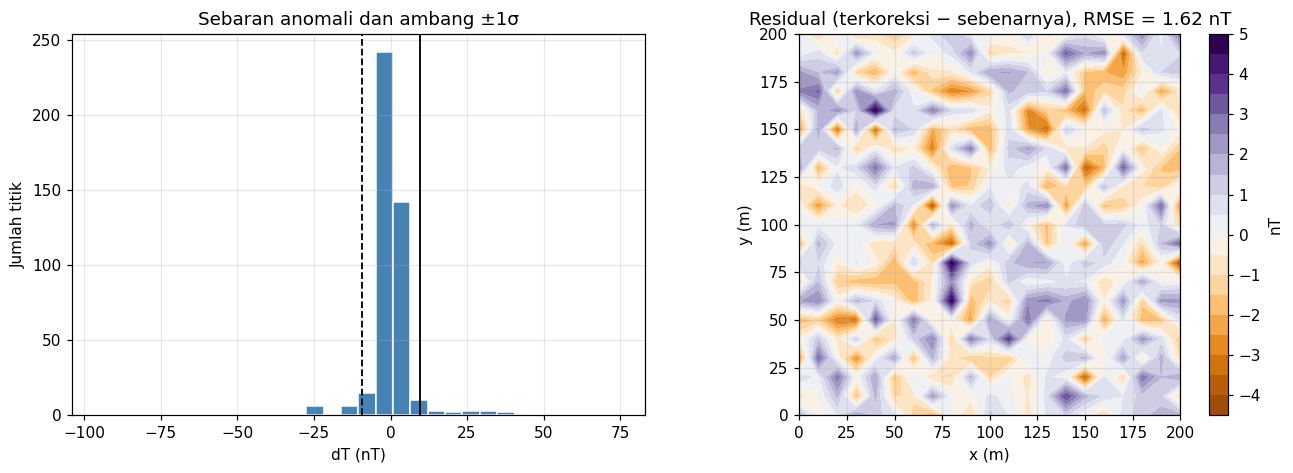

Verifikasi:
  1) IGRF di titik (x=100, y=100): 43502.20 nT  -> bandingkan dengan kalkulator IGRF NOAA (lokasi & tanggal yang sama)
  2) Satuan seluruh kolom: nT (konsisten)
  Catatan: anomali menunjukkan KONTRAS magnetisasi/suseptibilitas, bukan litologi pasti.

CHECK KRITERIA MUTU
  [LULUS] Data mentah tidak berubah
  [LULUS] Koreksi diurnal menurunkan RMSE
  [LULUS] RMSE terkoreksi < 3 nT
  [LULUS] Zona positif dekat benda 1 (<= 20 m)
  [LULUS] Zona negatif dekat benda 1 (<= 20 m)
  [LULUS] Zona dekat benda 2 (<= 20 m)

Status: Executed


In [7]:
# ======================================================================
# R-MAG-001 | Geomagnetik: koreksi diurnal + IGRF -> anomali residual -> zona anomali
# Mohammad Iqfar | H061251064 | Geofisika kelas B
#
# Cara menjalankan di VS Code:
#   (a) tombol Run (segitiga)  atau  python r-mag-001-geomagnetik.py
#       (tutup tiap jendela grafik untuk melihat grafik berikutnya)
#   (b) klik "Run Cell" pada setiap tanda  # %%  (hasil & grafik tampil di panel Interactive)
#
# Semua hasil DITAMPILKAN (terminal + 6 grafik). Tidak ada file yang dibuat.
# Paket: numpy, pandas, matplotlib   (pip install numpy pandas matplotlib)
# ======================================================================

# %% [BAGIAN 0] Import dan konfigurasi
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def tampil():
    """Tampilkan grafik LANGSUNG di VS Code (Interactive Window / Jupyter), tanpa menyimpan file.
    Grafik dirender ke memori (bukan ke disk) lalu ditampilkan. Jika dijalankan sebagai
    skrip biasa di terminal, grafik muncul di jendela matplotlib."""
    try:
        import io
        from IPython import get_ipython
        from IPython.display import display, Image
        if get_ipython() is not None:          # berjalan di Interactive Window / notebook
            fig = plt.gcf()
            buf = io.BytesIO()                 # buffer memori, BUKAN file
            fig.savefig(buf, format="png", dpi=110, bbox_inches="tight")
            display(Image(data=buf.getvalue()))
            plt.close(fig)
            return
    except ImportError:
        pass
    plt.show()

pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
pd.set_option("display.width", 140)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
SEED = 42
print("NumPy", np.__version__, "| pandas", pd.__version__)


# %% [BAGIAN 3A] Data survei sintetis: grid 21 x 21, spasi 10 m
rng = np.random.default_rng(SEED + 2)

# >>> GANTI DENGAN DATA ANDA: baca CSV (x, y, waktu_jam, F_obs) dan base station (waktu_jam, B)
IGRF_F0 = 43500.0            # nT  (PLACEHOLDER; ambil dari kalkulator IGRF NOAA)
IGRF_GRAD_X = 0.002          # nT/m ke timur  (placeholder)
IGRF_GRAD_Y = 0.020          # nT/m ke utara  (placeholder)
INC_DEG, DEC_DEG = -30.0, 0.0   # inklinasi & deklinasi (placeholder)

xs = np.arange(0, 201, 10.0)
ys = np.arange(0, 201, 10.0)
X, Y = np.meshgrid(xs, ys)

# arah medan utama (x = Timur, y = Utara, z = ke bawah)
I, D_ = np.radians(INC_DEG), np.radians(DEC_DEG)
Fhat = np.array([np.cos(I) * np.sin(D_), np.cos(I) * np.cos(D_), np.sin(I)])


def dipole_anomaly(X, Y, xs0, ys0, depth, A):
    """Anomali total-field benda terinduksi (pendekatan dipol/bola), nT."""
    rx, ry, rz = X - xs0, Y - ys0, -depth * np.ones_like(X)
    r = np.sqrt(rx ** 2 + ry ** 2 + rz ** 2)
    cosang = (Fhat[0] * rx + Fhat[1] * ry + Fhat[2] * rz) / r
    return A * (3 * cosang ** 2 - 1) / r ** 3


BODY1 = (80, 100, 15, 3.0e5)        # (x, y, kedalaman m, kekuatan A)
BODY2 = (150, 60, 10, -1.5e5)       # magnetisasi berlawanan
anom_true = dipole_anomaly(X, Y, *BODY1) + dipole_anomaly(X, Y, *BODY2)

# Waktu survei: 20 s per titik
n = X.size
t_hours = 9.0 + np.arange(n) * 20 / 3600
diurnal = 12 * np.sin(2 * np.pi * (t_hours - 6) / 24) + 4 * np.sin(2 * np.pi * (t_hours - 6) / 3)

igrf_grid = IGRF_F0 + IGRF_GRAD_X * X + IGRF_GRAD_Y * Y
F_obs = igrf_grid.ravel() + diurnal + anom_true.ravel() + rng.normal(0, 1.5, n)

# Base station: satu bacaan tiap 1 menit
tb = np.arange(t_hours[0] - 0.1, t_hours[-1] + 0.1, 1 / 60)
IGRF_BASE = IGRF_F0
B = IGRF_BASE + 12 * np.sin(2 * np.pi * (tb - 6) / 24) + 4 * np.sin(2 * np.pi * (tb - 6) / 3) \
    + rng.normal(0, 0.5, tb.size)

raw = pd.DataFrame({"x (m)": X.ravel(), "y (m)": Y.ravel(),
                    "waktu (jam)": t_hours, "F_obs (nT)": F_obs})
print("Data mentah (tidak diubah):", raw.shape)
print(raw.head().to_string(index=False))

# --- GRAFIK 1: data mentah (peta medan total + lintasan waktu survei)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.8))
sc = ax[0].scatter(raw["x (m)"], raw["y (m)"], c=raw["F_obs (nT)"], cmap="viridis", s=45)
plt.colorbar(sc, ax=ax[0], label="F_obs (nT)")
ax[0].set_title("Data mentah: medan magnet total")
sc2 = ax[1].scatter(raw["x (m)"], raw["y (m)"], c=raw["waktu (jam)"], cmap="plasma", s=45)
plt.colorbar(sc2, ax=ax[1], label="Waktu survei (jam)")
ax[1].set_title("Urutan akuisisi titik pengukuran")
for a in ax:
    a.set_xlabel("x (m)"); a.set_ylabel("y (m)"); a.set_aspect("equal")
plt.tight_layout()
tampil()


# %% [BAGIAN 3B] Koreksi diurnal -> koreksi IGRF -> anomali residual
data = raw.copy()                                          # data mentah dipertahankan
B_at_obs = np.interp(data["waktu (jam)"], tb, B)           # base station dipetakan ke waktu tiap titik
data["Koreksi diurnal (nT)"] = B_at_obs - IGRF_BASE
data["F_terkoreksi (nT)"] = data["F_obs (nT)"] - data["Koreksi diurnal (nT)"]
data["IGRF (nT)"] = IGRF_F0 + IGRF_GRAD_X * data["x (m)"] + IGRF_GRAD_Y * data["y (m)"]
data["Anomali dT (nT)"] = data["F_terkoreksi (nT)"] - data["IGRF (nT)"]

dT = data["Anomali dT (nT)"].to_numpy().reshape(X.shape)
dT_nodiurnal = F_obs.reshape(X.shape) - igrf_grid          # anomali TANPA koreksi diurnal (pembanding)
mu, sd = dT.mean(), dT.std()
rmse_corr = np.sqrt(np.mean((dT - anom_true) ** 2))
rmse_raw = np.sqrt(np.mean((dT_nodiurnal - anom_true) ** 2))
print(f"Statistik anomali: mean = {mu:.2f} nT | std = {sd:.2f} nT | min = {dT.min():.1f} | max = {dT.max():.1f}")
print(f"RMSE vs anomali sebenarnya: tanpa koreksi diurnal = {rmse_raw:.2f} nT | terkoreksi = {rmse_corr:.2f} nT")

# --- GRAFIK 2: variasi diurnal di base station
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(tb, B - IGRF_BASE, color="tab:blue", lw=1.2, label="Base station (variasi harian)")
ax.scatter(data["waktu (jam)"][::10], data["Koreksi diurnal (nT)"][::10], s=14, color="tab:red",
           zorder=3, label="Nilai koreksi pada waktu titik ukur (tiap 10 titik)")
ax.set_xlabel("Waktu (jam)"); ax.set_ylabel("Variasi (nT)")
ax.set_title("Variasi diurnal pada base station")
ax.legend(fontsize=8)
plt.tight_layout()
tampil()

# --- GRAFIK 3: tiga peta (sebenarnya, tanpa koreksi diurnal, terkoreksi) dengan skala warna sama
vmax = np.abs(anom_true).max()
fig, ax = plt.subplots(1, 3, figsize=(15, 4.4))
for a, Z, ttl in zip(ax, [anom_true, dT_nodiurnal, dT],
                     ["Anomali sebenarnya (sintetis)", "Tanpa koreksi diurnal",
                      "Anomali terkoreksi (diurnal + IGRF)"]):
    cs = a.contourf(X, Y, Z, levels=21, cmap="RdBu_r", vmin=-vmax, vmax=vmax)
    a.set_title(ttl, fontsize=10); a.set_xlabel("x (m)"); a.set_ylabel("y (m)"); a.set_aspect("equal")
    plt.colorbar(cs, ax=a, label="nT", shrink=0.85)
plt.tight_layout()
tampil()

# --- GRAFIK 4: profil melintasi benda 1 (y = 100 m) dan benda 2 (y = 60 m)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for a, yy in zip(ax, [100, 60]):
    j = int(np.argmin(np.abs(ys - yy)))
    a.plot(xs, anom_true[j], "k--", lw=1.5, label="Sebenarnya")
    a.plot(xs, dT_nodiurnal[j], color="tab:orange", marker="s", ms=4, lw=1, label="Tanpa koreksi diurnal")
    a.plot(xs, dT[j], color="tab:blue", marker="o", ms=4, lw=1.2, label="Terkoreksi")
    a.axhline(0, color="gray", lw=0.8)
    a.set_xlabel("x (m)"); a.set_ylabel("dT (nT)"); a.set_title(f"Profil y = {ys[j]:.0f} m")
    a.legend(fontsize=8)
plt.tight_layout()
tampil()


# %% [BAGIAN 3C] Identifikasi zona anomali signifikan (|dT - mean| > 1 sigma)
def label_regions(mask):
    """Beri nomor tiap kelompok sel 'True' yang saling bertetangga (flood-fill, 4 arah)."""
    lab = np.zeros(mask.shape, int)
    k = 0
    for i in range(mask.shape[0]):
        for j in range(mask.shape[1]):
            if mask[i, j] and lab[i, j] == 0:
                k += 1
                stack = [(i, j)]
                lab[i, j] = k
                while stack:
                    a, b = stack.pop()
                    for da, db in ((1, 0), (-1, 0), (0, 1), (0, -1)):
                        na, nb = a + da, b + db
                        if (0 <= na < mask.shape[0] and 0 <= nb < mask.shape[1]
                                and mask[na, nb] and lab[na, nb] == 0):
                            lab[na, nb] = k
                            stack.append((na, nb))
    return lab, k


rows = []
for sign, name in ((+1, "Positif"), (-1, "Negatif")):
    mask = sign * (dT - mu) > 1.0 * sd
    lab, k = label_regions(mask)
    for r in range(1, k + 1):
        sel = lab == r
        if sel.sum() < 3:                       # abaikan zona terlalu kecil (< 3 titik)
            continue
        idx = np.argmax(np.abs(np.where(sel, dT, 0)))
        iy, ix = np.unravel_index(idx, dT.shape)
        rows.append({"Zona": name, "Jumlah titik": int(sel.sum()), "Puncak dT (nT)": dT[iy, ix],
                     "x puncak (m)": xs[ix], "y puncak (m)": ys[iy]})
zones = pd.DataFrame(rows).sort_values("Puncak dT (nT)", key=np.abs, ascending=False).reset_index(drop=True)
print(zones.to_string())

# --- GRAFIK 5: peta zona signifikan + penanda puncak + posisi benda sebenarnya
fig, ax = plt.subplots(figsize=(7, 6))
cs = ax.contourf(X, Y, dT, levels=21, cmap="RdBu_r", vmin=-np.abs(dT).max(), vmax=np.abs(dT).max())
ax.contour(X, Y, dT, levels=[mu - sd, mu + sd], colors=["k", "k"], linestyles=["--", "-"], linewidths=1)
plt.colorbar(cs, ax=ax, label="nT")
for _, z in zones.iterrows():
    ax.plot(z["x puncak (m)"], z["y puncak (m)"], marker="o" if z["Zona"] == "Positif" else "s",
            ms=9, mfc="none", mec="k", mew=1.8)
    ax.annotate(f"{z['Puncak dT (nT)']:+.0f} nT", (z["x puncak (m)"], z["y puncak (m)"]),
                textcoords="offset points", xytext=(8, 8), fontsize=9, weight="bold")
for bx, by, *_ in (BODY1, BODY2):
    ax.plot(bx, by, marker="*", ms=16, color="gold", mec="k", label="Posisi benda sebenarnya")
h, l = ax.get_legend_handles_labels()
ax.legend(dict(zip(l, h)).values(), dict(zip(l, h)).keys(), loc="upper left", fontsize=8)
ax.set_aspect("equal"); ax.set_xlabel("x (m)"); ax.set_ylabel("y (m)")
ax.set_title("Zona signifikan: garis tegas = +1σ, putus-putus = −1σ")
plt.tight_layout()
tampil()

# --- GRAFIK 6: histogram dT dan peta residual (dT terkoreksi - sebenarnya)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.4))
ax[0].hist(dT.ravel(), bins=30, color="steelblue", edgecolor="white")
ax[0].axvline(mu + sd, color="k", lw=1.2); ax[0].axvline(mu - sd, color="k", lw=1.2, ls="--")
ax[0].set_xlabel("dT (nT)"); ax[0].set_ylabel("Jumlah titik"); ax[0].set_title("Sebaran anomali dan ambang ±1σ")
res = dT - anom_true
lim = np.abs(res).max()
cs = ax[1].contourf(X, Y, res, levels=21, cmap="PuOr", vmin=-lim, vmax=lim)
plt.colorbar(cs, ax=ax[1], label="nT")
ax[1].set_aspect("equal"); ax[1].set_xlabel("x (m)"); ax[1].set_ylabel("y (m)")
ax[1].set_title(f"Residual (terkoreksi − sebenarnya), RMSE = {rmse_corr:.2f} nT")
plt.tight_layout()
tampil()


# %% [BAGIAN 3D] Verifikasi (V) dan kriteria mutu (Q)
print("Verifikasi:")
print(f"  1) IGRF di titik (x=100, y=100): {IGRF_F0 + IGRF_GRAD_X * 100 + IGRF_GRAD_Y * 100:.2f} nT"
      "  -> bandingkan dengan kalkulator IGRF NOAA (lokasi & tanggal yang sama)")
print(f"  2) Satuan seluruh kolom: nT (konsisten)")
print("  Catatan: anomali menunjukkan KONTRAS magnetisasi/suseptibilitas, bukan litologi pasti.")

pos = zones[zones["Zona"] == "Positif"]
neg = zones[zones["Zona"] == "Negatif"]


def dekat(df_, bx, by, tol=20.0):
    return bool(len(df_) and np.min(np.hypot(df_["x puncak (m)"] - bx, df_["y puncak (m)"] - by)) <= tol)


checks = {
    "Data mentah tidak berubah": bool(np.allclose(raw["F_obs (nT)"], F_obs)),
    "Koreksi diurnal menurunkan RMSE": rmse_corr < rmse_raw,
    "RMSE terkoreksi < 3 nT": rmse_corr < 3.0,
    "Zona positif dekat benda 1 (<= 20 m)": dekat(pos, BODY1[0], BODY1[1]),
    "Zona negatif dekat benda 1 (<= 20 m)": dekat(neg, BODY1[0], BODY1[1]),
    "Zona dekat benda 2 (<= 20 m)": dekat(zones, BODY2[0], BODY2[1]),
}
print("\nCHECK KRITERIA MUTU")
for nama, ok in checks.items():
    print(f"  [{'LULUS' if ok else 'GAGAL'}] {nama}")
print("\nStatus:", "Executed" if all(checks.values()) else "Partial (ada check gagal)")